#### Apply CTF to specific image or to directory

Reference: https://github.com/geoffwoollard/learn_cryoem_math/blob/master/nb/2d_class_fourier.ipynb

In [1]:
import sys
sys.path.append("../")
import cv2
import numpy as np
import matplotlib.pyplot as plt
import generator.ctf_utils as ctf_utils

INFO:albumentations.check_version:A new version of Albumentations is available: 1.4.13 (you have 1.4.12). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


#### Choose and visualise image

In [2]:
file_path = 'train/12.png'

img = cv2.imread(file_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

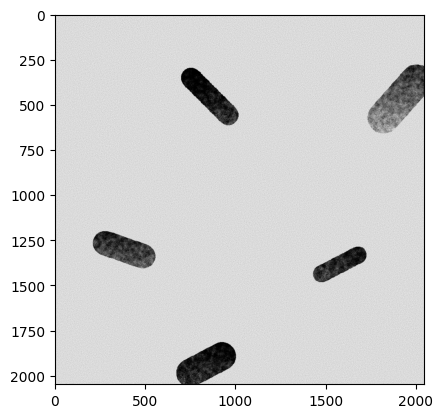

In [3]:
plt.imshow(img, cmap='gray')
plt.show()

#### Define parameters for CTF

In [4]:
psize_A = 1.4 # pixel size in angstrons
def1=5000 #1st prinicipal underfocus distance (Å).
def2=5000 #2nd principal underfocus distance (Å).
angast=0.01 #Angle of astigmatism (deg) from x-axis to azimuth.
phase=0.0 #Phase shift (deg).
kv=300 #Microscope acceleration potential (kV).
ac=0.07 #Amplitude contrast in [0, 1.0].
cs=1.4 #Spherical aberration (mm).
bf=0.0 #B-factor, divided by 4 in exponential, lowpass positive.
lp=0.0 #Hard low-pass filter (Å), should usually be Nyquist.

#### Apply CTF

In [5]:
image_2d_f = ctf_utils.do_fft(img)


s, a = ctf_utils.ctf_freq(img.shape, d=1/psize_A)

ctf_2d = np.fft.fftshift(ctf_utils.eval_ctf(s, a, 
                                            def1=def1, 
                                            def2=def2, 
                                            angast=angast, 
                                            phase=phase, 
                                            kv=kv, 
                                            ac=ac, 
                                            cs=cs, 
                                            bf=bf, 
                                            lp=lp))

image_2d_f_ctf = image_2d_f*ctf_2d

img_ctt = ctf_utils.do_ifft(image_2d_f_ctf)

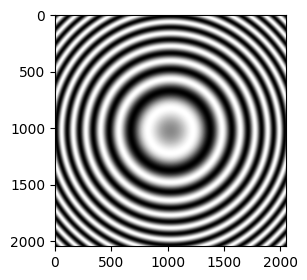

In [6]:
# Visualise CTF applied
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(ctf_2d, cmap='gray')
plt.show()

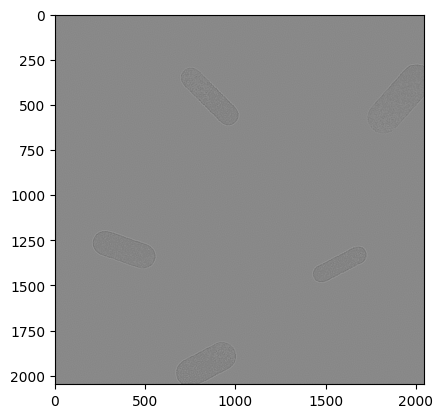

In [7]:
# Final image
plt.imshow(img_ctt, cmap='gray')
plt.show()

#### Combine CTF and original image

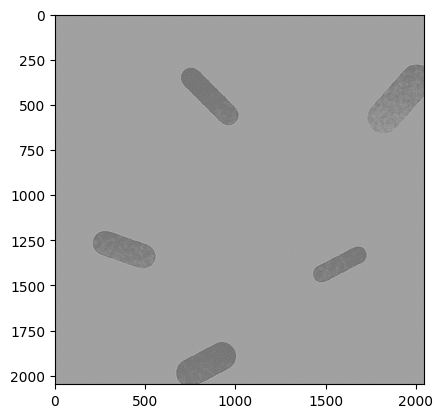

In [8]:
weight = 5

img_ctt_norm = ((img_ctt - np.min(img_ctt)) / ((np.max(img_ctt)) - np.min(img_ctt))).astype("float32")*255
                
img_combined = img + img_ctt_norm*weight

plt.imshow(img_combined, cmap='gray')
plt.show()

#### Apply to all images in directory

In [9]:
import os

path = 'train/'

In [11]:
combineImages = True

weight = 3

for count, image_name in enumerate(os.listdir(path)):

    if image_name.endswith(('.jpg', '.png', '.jpeg', '.tiff')):

        image = cv2.imread(path + '/' + image_name)
                        
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        image_2d_f = ctf_utils.do_fft(image)

        s, a = ctf_utils.ctf_freq(image.shape, d=1/psize_A)

        ctf_2d = np.fft.fftshift(ctf_utils.eval_ctf(s, a, 
                                                def1=def1, 
                                                def2=def2, 
                                                angast=angast, 
                                                phase=phase, 
                                                kv=kv, 
                                                ac=ac, 
                                                cs=cs, 
                                                bf=bf, 
                                                lp=lp))
        
        image_2d_f_ctf = image_2d_f*ctf_2d

        img_ctt = ctf_utils.do_ifft(image_2d_f_ctf)

        img_ctt = ((img_ctt - np.min(img_ctt)) / ((np.max(img_ctt)) - np.min(img_ctt))).astype("float32")*255

        if combineImages == True:

            img_ctt = image + img_ctt*weight

            img_ctt = ((img_ctt - np.min(img_ctt)) / ((np.max(img_ctt)) - np.min(img_ctt))).astype("float32")*255

        cv2.imwrite(path  + '/ctf_' + image_name, img_ctt) # save image as copy